# IMPORT

In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
import json
import time
from shapely.geometry import box,LineString,Point,MultiPoint,MultiLineString,MultiPolygon,Polygon
from shapely.ops import unary_union
import socket
from collections import defaultdict
current_dir = os.path.join(os.getcwd()) 
mother_path = os.path.abspath(os.path.join(current_dir, os.pardir))
print('mother_path:', mother_path)
sys.path.append(os.path.join(mother_path, 'PreProcessing'))
sys.path.append(os.path.join(mother_path))
from FittingProcedures import *
from plot import *
from Potential import *
from Grid import *
from PreprocessingObj import *
from ODfromfma import *
import time
from GeometrySphere import *
from Polycentrism import *
#import rustworkx as rw
import ast
from PolycentrismPlot import *
## BASIC PARAMS
plt.rcParams.update({
    "text.usetex": False,
})

if socket.gethostname()=='artemis.ist.berkeley.edu':
    TRAFFIC_DIR = '/home/alberto/LPSim/traffic_phase_transition'
else:
    TRAFFIC_DIR = os.getenv('TRAFFIC_DIR')
name = 'BOS'
grid_size = 0.02
hexagon_resolution = 8
dir_grid = os.path.join(TRAFFIC_DIR,'data','carto',name,'grid',str(grid_size))

## BASIC NEEDED OBJECTS
SFO_obj = GeometricalSettingsSpatialPartition(name,TRAFFIC_DIR)
bbox = SFO_obj.bounding_box
minx, miny, maxx, maxy = bbox
dir_geometries = os.path.join(TRAFFIC_DIR,'data','carto','{0}'.format(name))
grid = GetGrid(grid_size,SFO_obj.bounding_box,'EPSG:4326',dir_geometries)
df_distance,FoundDistMat = GetDirectionMatrix(dir_geometries,grid_size)
Tij = GetODGrid(dir_geometries,str(grid_size))
lattice = nx.read_graphml(os.path.join(dir_grid,"centroid_lattice.graphml"))
#VectorField = pd.read_csv('/home/alberto/LPSim/traffic_phase_transition/data/carto/BOS/grid/0.02/VectorField.csv')
#Potential = pd.read_csv('/home/alberto/LPSim/traffic_phase_transition/data/carto/BOS/grid/0.02/PotentialDataFrame.csv')

# GET POTENTIAL AND VECTOR FIELD
VectorField = GetVectorField(Tij,df_distance)
VectorFieldDir = os.path.join(TRAFFIC_DIR,'data','carto',name,'grid',str(grid_size))
lattice = GetPotentialLattice(lattice,VectorField)
lattice = SmoothPotential(lattice)
PotentialDataframe = ConvertLattice2PotentialDataframe(lattice)
PotentialDataframe = CompletePotentialDataFrame(VectorField,grid,PotentialDataframe)
PlotHarmonicComponentDistribution(grid,PotentialDataframe,dir_grid,verbose = False)


In [3]:
#import swifter
# Assuming gdf_polygons and grid are GeoDataFrames
# gdf_polygons contains polygons of the geographic area
# grid contains polygons covering the bounding box taken from the unary union

# Perform a spatial join to get the boundary of gdf_polygons
boundary = gpd.overlay(SFO_obj.gdf_polygons, SFO_obj.gdf_polygons, how='union',keep_geom_type=False).unary_union
boundary = boundary.simplify(0.01)

if isinstance(boundary, Polygon):
    boundary_line = LineString(boundary.exterior.coords)
elif isinstance(boundary, MultiPolygon):
    exterior_coords = []
#    for i,polygon in boundary.geoms:
    polygon = boundary.geoms[0]
    exterior_coords.extend(polygon.exterior.coords)
    boundary_line = LineString(exterior_coords)
grid['position'] = grid.geometry.apply(lambda x: 'inside' if x.within(boundary) else ('edge' if x.touches(boundary) else 'outside'))
grid['relation_to_line'] = grid.geometry.apply(lambda poly: 'edge' if boundary_line.crosses(poly) else 'not_edge')

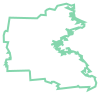

In [3]:
'''
{'logk': 0.0003055803472447064, 'alpha': 0.0002546775749831938, 'gamma': -0.07627729954795813, '1/d0': 4.8774299414384545}
Number centers considered:  2
[ 3.37484752 51.76501691]
bin index:  2
Length filtered grid:  32  rv:  3.3748475174250743
bin index:  23
Length filtered grid:  60  rv:  51.76501690675754
New population:  574776957.9199114
k:  1.0003056270416752  alpha:  0.0002546775749831938  beta:  -0.07627729954795813  d0:  4.8774299414384545
<k*p>:  165358.83
<p**alpha>:  1.0017573
<p**beta>:  0.6491281
<exp(-d/d0)>:  0.010571069

'''


# COMPUTE CENTRALITY INDEX (PI)

In [ ]:
from tqdm import tqdm
from Polycentrism import *
SumPot = np.sum(PotentialDataframe['V_out']) 
NumGridEdge = grid[grid['relation_to_line']=='edge'].shape[0]
IndexEdge = PotentialDataframe[PotentialDataframe['V_out']>0]['index'].values
print('Number of edge grids:',NumGridEdge)
print('Number of grids in potential: ',len(IndexEdge))
distance_vector,potential_vector = PrepareJitCompiledComputeV(df_distance,GetIndexEdgePolygon(grid),SumPot,NumGridEdge,PotentialDataframe,case = 'Vmax')
plt.hist(potential_vector,bins = 100)
plt.xlabel('Potential')
plt.show()
plt.hist(distance_vector,bins = 100)
plt.xlabel('Distance')
plt.show()
print(np.unique(potential_vector))
print('shape distance vector Vmax: ',len(distance_vector))
print('shape potential vector Vmax: ',len(potential_vector))
Vmax = ComputeJitV(distance_vector,potential_vector)
print('Vmax: ',Vmax)
distance_vector,potential_vector = PrepareJitCompiledComputeV(df_distance,IndexEdge,SumPot,NumGridEdge,PotentialDataframe,case = 'V')
plt.hist(potential_vector,bins = 100)
plt.xlabel('Potential')
plt.show()
plt.hist(distance_vector,bins = 100)
plt.xlabel('Distance')
plt.show()

print('shape distance vector V: ',len(distance_vector))
print('shape potential vector V: ',len(potential_vector))
V = ComputeJitV(distance_vector,potential_vector)
print('V: ',V)
PI = ComputePI(V,Vmax)
print('PI: ',PI)

In [5]:
print('MaxV:',Vmax)
print('SumPot:',SumPot)
print('NumGridEdge:',NumGridEdge)
print('SumPot/MaxV:',SumPot/Vmax)


MaxV: 69.81662965783289
SumPot: 664340534.9493425
NumGridEdge: 417
SumPot/MaxV: 9515505.66398343


# MODIFY POPULATION 

In [48]:
def polar_coordinates(point, center):
    y = point[1] - center[1]#ProjCoordsTangentSpace(center[0],center[1],point[0],point[1])
    x = point[0] - center[0]
    r = np.sqrt(x**2 + y**2)/1000
    # Calculate θ
    theta = np.arctan(y/x)
    
    # Adjust θ to be positive
#    theta = (theta + 2 * np.pi) % (2 * np.pi)
    # Round r and θ to the nearest steps
#    r = round(r / r_step) * r_step
#    theta = round(theta / theta_step) * theta_step
    return r, theta

def GenerateIndexCenters(grid,num_peaks):
    '''
        Generate random centers given number of them exponentially from the center.
    '''
    if 'is_populated' not in grid.columns:
        grid['is_populated'] = grid['population']>0
    if 'coords' not in grid.columns:
        grid['coords'] = grid.apply(lambda x: ProjCoordsTangentSpace(x['centroidx'],x['centroidy'],coords_center[0],coords_center[1]),axis = 1)
        grid['distance_from_center'] = grid.apply(lambda x: polar_coordinates(np.array([x['centroidx'],x['centroidy']]),np.array(x['coords']))[0],axis = 1)
    index_centers = []

    scale = np.mean(grid.loc[grid['is_populated']]['distance_from_center'])
    populated_grid = grid.loc[grid['is_populated']]
    # PICK RANDOMLY THE CENTERS (with exponentially decreasing probability in distance from center)
    random_values = np.random.exponential(scale,num_peaks)
    hist, bin_edges = np.histogram(populated_grid['distance_from_center'].to_numpy(), bins=30)
#    print(random_values)
    for rv in random_values:
        if rv > bin_edges[-1]:
            while(rv >= bin_edges[-1]):
                rv = np.random.exponential(scale)
#                print('extracting rv: ',rv)
                bin_index = np.digitize(rv, bin_edges)
#                print('bin index: ',bin_index)     
                filtered_grid = populated_grid[(populated_grid['distance_from_center'] >= bin_edges[bin_index - 1])] 
                filtered_grid = filtered_grid[filtered_grid['distance_from_center'] < bin_edges[bin_index]]   
#                print('Distance from center extracted: ',rv,'Number of grids available: ',len(filtered_grid))
        else:
            bin_index = np.digitize(rv, bin_edges)
#            print('bin index: ',bin_index)     
            filtered_grid = populated_grid[(populated_grid['distance_from_center'] >= bin_edges[bin_index - 1])] 
            filtered_grid = filtered_grid[filtered_grid['distance_from_center'] < bin_edges[bin_index]]        
#            print('Length filtered grid: ',len(filtered_grid), ' rv: ',rv)
        if filtered_grid.shape[0] == 0:
            print('Empty bin')
        else:
            selected_row = filtered_grid.sample()
            # Step 6: Get the index of the selected row
            selected_index = selected_row['index'].values[0]
#            print('Grid selected: ',selected_index)
            index_centers.append(selected_index)
    return index_centers

def SetCovariances(index_centers):
    '''
        Set the covariance matrix for each center.
        Distribute the same quantity of people for each center with different covariances.
    '''
    covariances = []
    for i in range(len(index_centers)):
        rvs = [[np.random.uniform(2,15),0],[0,np.random.uniform(2,15)]]
        covariances.append(rvs)
    return covariances

#@numba.njit(['(float32[:], float32[:], float32,float32,float32,float32)'],parallel=True)
def GravitationalModel(population,df_distance,k,alpha,beta,d0):
    print('k: ',k,' alpha: ',alpha,' beta: ',beta,' d0: ',d0)
    print('<k*p>: ',np.mean(k*population))
    print('<p**alpha>: ',np.mean(population**alpha))
    print('<p**beta>: ',np.mean(population**beta))
    print('<exp(-d/d0)>: ',np.mean(np.exp(df_distance*d0)))
    print('<k*population**(alpha)*population**(beta)>: ',np.mean(k*np.tensordot(population**(alpha),population**(beta),axes = 0)))
    kMiMjedij = np.zeros(len(population)*len(population),dtype=np.float32)
    count_close_centers = 0
    for i in range(len(population)):
        for j in range(len(population)):
            if int(population[i])!=0 and int(population[j])!=0 and np.exp(df_distance[i*len(population) + j]*d0)>10**(-4):
                print('pop i: ',population[i],' pop j: ',population[j])
                print('dij: ',df_distance[i*len(population) + j])
                print('kMiMj: ',k*population[i]**(alpha)*population[j]**(beta))
                print('exp(dij/d0): ',np.exp(df_distance[i*len(population) + j]*d0))
                print('kMiMjedij: ',k*population[i]**(alpha)*population[j]**(beta)*np.exp(df_distance[i*len(population) + j]*d0))
                kMiMjedij[i*len(population) + j] += k*population[i]**(alpha)*population[j]**(beta)*np.exp(df_distance[i*len(population) + j]*d0)
                count_close_centers += 1
            else:
                kMiMjedij[i*len(population) + j] = 0
    print('Number of close centers: ',count_close_centers)
#    kMiMjedij = [k*population[i]**(alpha)*population[j]**(beta)*np.exp(-df_distance[i*len(population) + j]/d0) for i in range(len(population)) for j in range(len(population))]
    return kMiMjedij


# PLOT MASSES

In [ ]:
import numpy as np
from scipy.stats import multivariate_normal


## TODO: Decide the number of centers, redistribute the population according to some variance,
##      COMPUTE WITH GRAVITY FLUXES
##      NORMALIZE THEM
##      COMPUTE VECTOR FIELD
##      COMPUTE POTENTIAL
##      CREATE OD FILE IN THE MEAN WHILE
##      SAVE EVERYTHING ON FOLDER WITH POTENTIAL


idx2array = {j*57+ i: [i,j] for j in range(57) for i in range(61)}
# Set the number of peaks
num_peaks = 4
# CENTER
coords_center,center_idx = ExtractCenterByPopulation(grid)
arrayid = idx2array[center_idx]
# CENTER 2
arrayid2 = [arrayid[0] + 10 ,arrayid[1] -7]
coords_center2 = [grid['centroidx'][ExtractKeyFromValue(idx2array,arrayid2)],grid['centroidy'][ExtractKeyFromValue(idx2array,arrayid2)]]
arrayid2 = [arrayid[0] -8 ,arrayid[1] + 10]
coords_center3 = [grid['centroidx'][ExtractKeyFromValue(idx2array,arrayid2)],grid['centroidy'][ExtractKeyFromValue(idx2array,arrayid2)]]
arrayid2 = [arrayid[0] -10 ,arrayid[1] -15]
coords_center4 = [grid['centroidx'][ExtractKeyFromValue(idx2array,arrayid2)],grid['centroidy'][ExtractKeyFromValue(idx2array,arrayid2)]]

# Set the mean and covariance matrix for each peak
means = np.array([[coords_center[0], coords_center[1]], [coords_center2[0], coords_center2[1]],[coords_center3[0], coords_center3[1]],[coords_center4[0], coords_center4[1]]])
covariances = np.array([[[10, 0], [0, 4.5]], [[5, 0], [0, 9]], [[6, 0], [0, 9]], [[7, 0], [0, 8]]])
centers = np.array([coords_center, coords_center2,coords_center3,coords_center4])
# Generate the potential values for each grid
potential_values = np.zeros(len(grid))
count_center = 0
for center in centers:
    for i in range(len(grid)):
        point = np.array([grid['centroidx'][i], grid['centroidy'][i]])
#        print('Coords Projected: ',ProjCoordsTangentSpace(center[0],center[1],point[0],point[1]))
#        print('norm: ',np.linalg.norm(ProjCoordsTangentSpace(center[0],center[1],point[0],point[1]))**2)
#        print('covariance: ',covariances[count_center][0][0]**2 + covariances[count_center][1][1]**2)
        potential_values[i] += 187652*np.exp(-(np.linalg.norm(ProjCoordsTangentSpace(center[0],center[1],point[0],point[1]))/(10**3))**2/(covariances[count_center][0][0]**2 + covariances[count_center][1][1]**2))/2#multivariate_normal.pdf(grid_center, mean=means[j], cov=covariances[j])
        print('distance squared: ',(np.linalg.norm(ProjCoordsTangentSpace(center[0],center[1],point[0],point[1]))/(10**3))**2)
        print('covariance: ',(covariances[count_center][0][0]**2 + covariances[count_center][1][1]**2))
        print('fraction: ',(np.linalg.norm(ProjCoordsTangentSpace(center[0],center[1],point[0],point[1]))/(10**3))**2/(covariances[count_center][0][0]**2 + covariances[count_center][1][1]**2))        
        print('potential: ',potential_values[i])
    count_center += 1
plt.hist(potential_values, bins=100)
plt.show()
print('Number pot: ',len(potential_values[potential_values>0]))
# Add the new column to the potentialdataframe
PotentialDataframe['new_potential'] = potential_values


# These below are the plots of the potential in the thesis

In [ ]:
import contextily as ctx
import matplotlib.pyplot as plt
import geopandas as gpd
import pandas as pd
import os
from shapely.geometry import box

Cities = ["BOS", "RIO", "SFO", "LIS"]
traffic_dir = os.environ["TRAFFIC_DIR"]
carto_dir = os.path.join(traffic_dir, "data", "carto")
City2bbox = {
    "LIS": [-9.6, 38.50, -8.9, 39.1],
    "SFO": [-122.7, 36.9, -121.6, 38.4],
    "RIO": [-43.795449, -23, -42.9, -22.78],
}

for city in Cities:
    city_dir = os.path.join(carto_dir, city)
    grid_dir = os.path.join(city_dir, "grid", "0.02")
    PotentialDataframe = pd.read_csv(os.path.join(grid_dir, "PotentialDataFrame.csv"))
    grid = gpd.read_file(os.path.join(grid_dir, "grid.geojson"))
    grid['potential'] = PotentialDataframe['V_out']

    # Filter by bounding box
    if city in City2bbox.keys():
        bbox = box(*City2bbox[city])
        grid = grid.loc[grid.geometry.within(bbox)]
        print(grid.empty)
    crs = "EPSG:3857"
    # Reproject to Web Mercator (EPSG:3857)
    grid.to_crs(crs=crs, inplace=True)

    # Modify potential values for SFO
    if city == "SFO":
        grid["potential"] = grid["potential"].to_numpy() * (-1)

    # Plot contour map
    fig, ax = plt.subplots(1, 1, figsize=(15, 15))
    contour_filled = ax.tricontourf(
        grid['geometry'].apply(lambda geom: geom.centroid.x),
        grid['geometry'].apply(lambda geom: geom.centroid.y),
        grid['potential'],
        cmap='inferno',
        alpha=0.3
    )
#    contour_lines = ax.tricontour(grid['geometry'].apply(lambda geom: geom.centroid.x), 
#                                grid['geometry'].apply(lambda geom: geom.centroid.y), 
#                                grid['potential'], colors='black',fontsize=15)

    # Add colorbar
    cbar = plt.colorbar(contour_filled, ax=ax)
    cbar.set_label('Potential', fontsize=15)

    # Set axis labels and title
    ax.set_xlabel('Longitude', fontsize=15)
    ax.set_ylabel('Latitude', fontsize=15)

    # Add basemap with a valid zoom level
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, zoom=12)  # Set a valid zoom level
    plt.tight_layout()  # Ensure the figure matches the axis size
    plt.savefig(os.path.join(grid_dir, "contour_map.png"), dpi=200)
    plt.show()
    plt.close(fig)

# Here below plots of the rotor and harmonic components in thesis

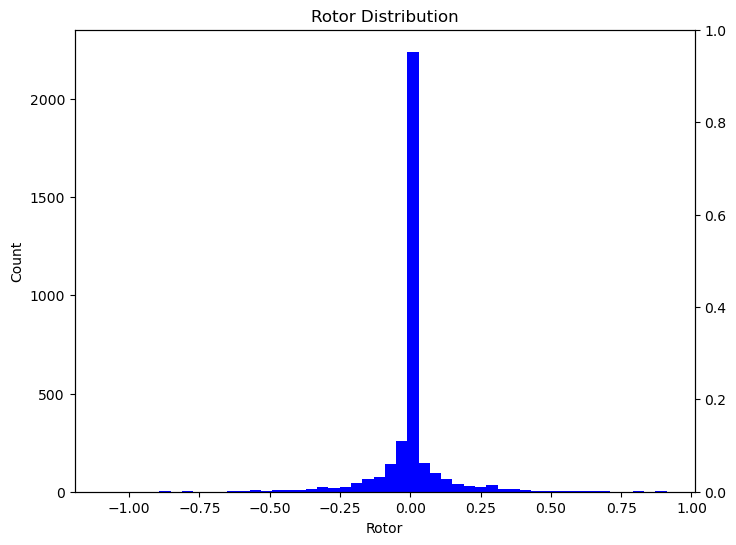

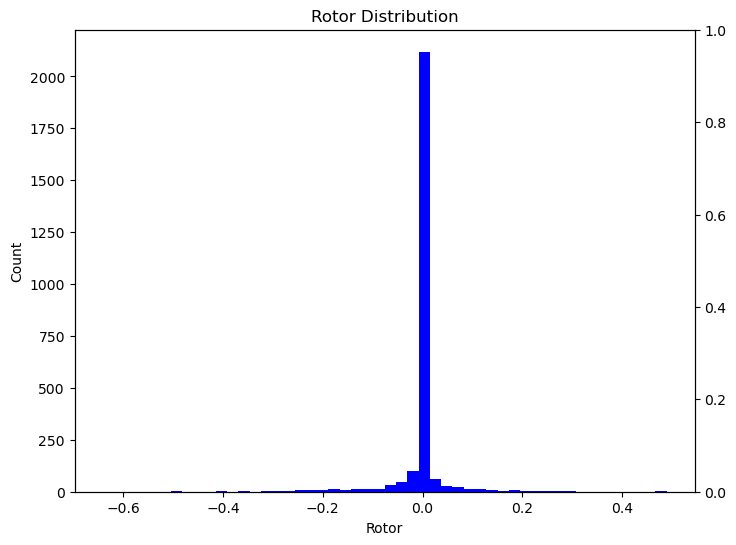

In [13]:

from PolycentrismPlot import *
import matplotlib.pyplot as plt
import os
def PlotRotorDistribution(grid, PotentialDataframe, grid_dir, UCI):
    fig, ax = plt.subplots(figsize=(8, 6))
    twin = ax.twinx()

    ax.hist(grid['rotor'],bins = 50, color = 'blue',label = 'Rotor')
    ax.set_title('Rotor Distribution')
    ax.set_xlabel('Rotor')
    ax.set_ylabel('Count')
#    ax.set_xlim(-1, 1)
    plt.savefig(os.path.join(grid_dir,f'RotorDistr_{round(UCI,3)}.png'),dpi = 200)

Cities = ["BOS","RIO"]
traffic_dir = os.environ["TRAFFIC_DIR"]
carto_dir = os.path.join(traffic_dir, "data", "carto")
City2UCI = {
    "BOS": 0.216,
    "RIO": 0.48,
}
for city in Cities:
    city_dir = os.path.join(carto_dir, city)
    grid_dir = os.path.join(city_dir, "grid", "0.02")
    PotentialDataframe = pd.read_csv(os.path.join(grid_dir, "PotentialDataFrame.csv"))
    grid = gpd.read_file(os.path.join(grid_dir, "grid.geojson"))
    grid['potential'] = PotentialDataframe['V_out']
    if 'rotor' in grid.columns:
        pass
    else:
        grid['rotor'] = PotentialDataframe['rotor_z_out']
    grid = grid[grid["rotor"] < 1 ]
    PlotRotorDistribution(grid,PotentialDataframe,grid_dir,City2UCI[city])
#    PlotHarmonicComponentDistribution(grid,PotentialDataframe,grid_dir,City2UCI[city])


7

# GET Vec Field & Pot

In [ ]:
ComputeInitPotential = True
ComputeInitVF = True
if ComputeInitVF:
    VectorField = GetVectorField(Tij,df_distance)
    VectorFieldDir = os.path.join(TRAFFIC_DIR,'data','carto',name,'grid',str(grid_size))
    SaveVectorField(VectorField,VectorFieldDir)

if ComputeInitPotential:
    lattice = GetPotentialLattice(lattice,VectorField)
    lattice = SmoothPotential(lattice)
    PotentialDataframe = ConvertLattice2PotentialDataframe(lattice)
    PotentialDataframe = CompletePotentialDataFrame(VectorField,grid,PotentialDataframe)
    SavePotentialDataframe(PotentialDataframe,dir_grid)


# Generation Population

In [1]:
# O
import os
# F
# A 
import ast
# C
from collections import defaultdict
# G
import gc
# J
import json
# L
import logging
import logging.handlers
# M
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from multiprocessing import Pool,Queue,Barrier,cpu_count,Manager,Process,Value,log_to_stderr
import ctypes
# P
import psutil
# S
import socket
import sys
# T
import time

TRAFFIC_DIR = os.environ["TRAFFIC_DIR"]
current_dir = os.path.join(os.getcwd()) 
mother_path = os.path.abspath(os.path.join(current_dir, os.pardir))
print('mother_path:', mother_path)
sys.path.append(os.path.join(mother_path, 'PreProcessing'))
sys.path.append(os.path.join(mother_path))
sys.path.append(os.path.join(TRAFFIC_DIR,'scripts','GeometrySphere'))
sys.path.append(os.path.join(TRAFFIC_DIR,'scripts','ServerCommunication'))
sys.path.append(os.path.join(TRAFFIC_DIR,'scripts','PostProcessingSimulations'))
sys.path.append(os.path.join(TRAFFIC_DIR,'scripts',"InitialConfigProcess"))

# Project specific
# A
from AlgorithmCheck import *
# C
from ComputeGrid import *
from ComputeHexagon import *
from ConcurrencyManager import *
# F
from FittingProcedures import *
# G
from GeometrySphere import *
from GenerateModifiedFluxesSimulation import *
from GravitationalFluxes import *                                               # FIT section
from Grid import *
# H 
from Hexagon import *
if socket.gethostname()=='artemis.ist.berkeley.edu':
    sys.path.append(os.path.join('/home/alberto/LPSim','traffic_phase_transition','scripts','ServerCommunication'))
else:
    sys.path.append(os.path.join(os.getenv('TRAFFIC_DIR'),'scripts','ServerCommunication'))
from HostConnection import *
# M
from MainPolycentrism import *
from ModifyPotential import *
from multiple_launches import *
# O 
from ODfromfma import *
# P
from plot import *
from Polycentrism import *
from PolycentrismPlot import *
from PolygonSettings import *
from Potential import *
from PreprocessingObj import *
# Post Processing
from TrajectoryAnalysis import *
from GenerateConfiguraiton import *


from threading import Thread,Lock
import threading
import queue
import subprocess
## BASIC PARAMS

mother_path: /home/alberto/LPSim/traffic_phase_transition/scripts
mother_path: /home/alberto/LPSim/traffic_phase_transition/scripts
PyMC3 not installed


In [ ]:
def LocalMain(CityName,TRAFFIC_DIR):
    City2RUCI = {CityName: {"UCI": [], "R": []}}
    # Everything is handled inside the object
    GeoInfo = GeometricalSettingsSpatialPartition(CityName,TRAFFIC_DIR)
    # Compute the Geometries
    GeoInfo.GetGeometries()
    # Compute the Potential and Vector field for non modified fluxes
    UCI = GeoInfo.RoutineVectorFieldAndPotential()
    # Compute the Fit for the gravity model
    GeoInfo.ComputeFit()
    # Initialize the Concatenated Df for Simulation [It is common for all different R]
    GeoInfo.InitializeDf4Sim()
    GeoInfo.ComputeEndFileInputSimulation()
    GeoInfo.GeneratePopulationAndSetUCIs()
NameCities = ["LAX"]#["LIS","LAX","SFO","RIO","BOS"]
#with Pool(len(NameCities)) as p:
#    p.starmap(LocalMain,[(NameCity,TRAFFIC_DIR) for NameCity in NameCities])

for CityName in NameCities:
    City2RUCI = {CityName: {"UCI": [], "R": []}}
    # Everything is handled inside the object
    GeoInfo = GeometricalSettingsSpatialPartition(CityName,TRAFFIC_DIR)
    # Compute the Geometries
    GeoInfo.GetGeometries()
    # Compute the Potential and Vector field for non modified fluxes
    UCI = GeoInfo.RoutineVectorFieldAndPotential()
    # Compute the Fit for the gravity model
    GeoInfo.ComputeFit()
    # Initialize the Concatenated Df for Simulation [It is common for all different R]
    GeoInfo.InitializeDf4Sim()
    GeoInfo.ComputeEndFileInputSimulation()
    GeoInfo.GeneratePopulationAndSetUCIs()


In [33]:
def RuleNewIndices(grid,case):
    if case == "min":
        mincentroidy = min(grid['centroidy'])
        ismincentroidy = grid['centroidy']==mincentroidy
        isbiggerminx = grid['centroidx']>-118.83
        issmallermaxx = grid['centroidx']<-117.9
        log_and = np.logical_and(ismincentroidy,isbiggerminx)
        log_and = np.logical_and(log_and,issmallermaxx)
        idceslowestcentroidy = grid[log_and]['index'].values


    return idceslowestcentroidy

def ModifyEdgesAdHocLAX(grid):
    """
        Modify the edges of the grid for LAX
        Consider in particular edges the bottom of the figure since 
        it is a cut of the initial cartography.    
    """
    idceslowestcentroidy = RuleNewIndices(grid,"min")
    IsEdgeMin = grid['index'].apply(lambda x: x in idceslowestcentroidy)
    grid["temporary_relation_to_line"] = ["edge" if x else "not_edge" for x in IsEdgeMin]
    grid["relation_to_line"] = ["edge" if (x["relation_to_line"] == "edge") or (x["temporary_relation_to_line"] == "edge") else  "not_edge" for i,x in grid.iterrows()]

    grid = grid.drop(columns = ["temporary_relation_to_line"])
    return grid


248


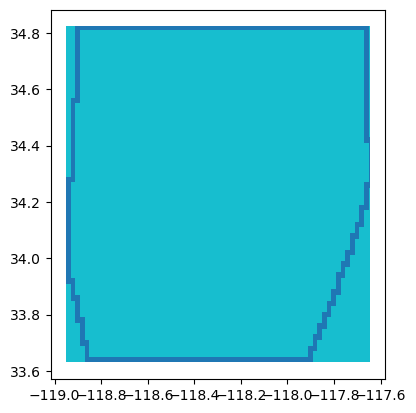

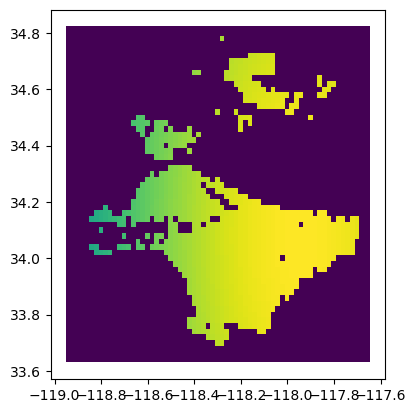

In [34]:
import geopandas as gpd
import polars as pl
import numpy as np
grid = gpd.read_file("/home/alberto/LPSim/traffic_phase_transition/data/carto/LAX/grid/0.02/grid.geojson")
g = pl.read_parquet("/home/alberto/LPSim/traffic_phase_transition/data/carto/LAX/Grid_0.12.parquet")
grid = grid.cx[-118.951721: -117.646374, 33.65004:34.823301]
grid["population"] = g["population"].to_numpy()
grid = ModifyEdgesAdHocLAX(grid)
#grid = grid.drop(columns = ["temporary_relation_to_line"])
grid.plot(column='relation_to_line')
grid.plot(column='population')
print(np.sum(grid['relation_to_line'] == "edge"))



In [5]:
dm

,i,j,dir_vector,distance
i64,i64,i64,str,f64
0,0,0,"""[nan nan]""",0.0
1,0,1,"""[0. 1.]""",2.223902
2,0,2,"""[0. 1.]""",4.447803
3,0,3,"""[0. 1.]""",6.671705
4,0,4,"""[0. 1.]""",8.895606
…,…,…,…,…
47114491,6863,6859,"""[ 0. -1.]""",8.520935
47114492,6863,6860,"""[ 0. -1.]""",6.297033
47114493,6863,6861,"""[ 0. -1.]""",4.073131
